<h2 align="center">Mini Project: QuickBite Analysis using Python<h2>

**Business Problem**

QuickBite wants to examine payment method preferences (Debit Card, Credit Card, UPI, Cash) and measure failure and pending rates across payment gateways and order basket sizes. The objective is to identify transaction failure points and recommend platform improvements to reduce checkout drop-offs and lost sales.

**Import Libraries**   

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

**Data Loading**

In [2]:
payments = pd.read_csv("Cleaned_Payments.csv")
orders = pd.read_csv("Cleaned_Orders.csv")

**Merge Payments with Orders**

**Merge Payments and Orders table**   

In [3]:
master_data = payments.merge(
    orders,
    on="order_id",
    how="left"
)
print("Master data shape:", master_data.shape)
master_data.head()

Master data shape: (50, 12)


,payment_id,order_id,payment_method,payment_status,payment_date,customer_id,restaurant_id,order_date,order_status,delivery_minutes,order_amount,discount
0,1,1,Credit Card,Paid,2025-06-19,13,15,2025-06-19,Delivered,36.0,466.43,75
1,2,2,Cash,Pending,2025-07-04,18,18,2025-07-04,Delivered,67.0,1156.11,50
2,3,3,UPI,Paid,2025-06-29,13,12,2025-06-29,Delivered,28.0,1039.77,0
3,4,4,Credit Card,Paid,2025-09-19,25,2,2025-09-19,Delivered,27.0,486.90,0
4,5,5,Debit Card,Paid,2025-08-16,22,14,2025-08-16,Pending,24.0,846.39,50


**Check missing values in merged dataset**

In [4]:
master_data.isnull().sum()

payment_id          0
order_id            0
payment_method      0
payment_status      0
payment_date        0
customer_id         0
restaurant_id       0
order_date          0
order_status        0
delivery_minutes    0
order_amount        0
discount            0
dtype: int64

**Feature Engineering: Net Revenue & Order Basket Bins**

**CreateNet Revenue & Order Size Bins**

**Net Revenue = Order Amount − Discount**

In [ ]:
master_data["NetRevenue"] = (
    master_data["order_amount"]
    - master_data["discount"]
)

# Categorize order sizes into practical basket bins
master_data["OrderSizeBin"] = pd.cut(
    master_data["order_amount"],
    bins=[0, 500, 1000, 1500, np.inf],
    labels=["Low (<500)", "Medium (500-1000)", "High (1000-1500)", "Very High (>1500)"]
)

master_data[["payment_id", "payment_method", "payment_status", "order_amount", "NetRevenue", "OrderSizeBin"]].head()

**Overall Payment KPI Analysis**

In [6]:
total_transactions = master_data["payment_id"].count()
successful_payments = (master_data["payment_status"] == "Paid").sum()
pending_payments = (master_data["payment_status"] == "Pending").sum()
failed_payments = (master_data["payment_status"] == "Failed").sum()

overall_success_rate = (successful_payments / total_transactions) * 100
overall_failure_rate = (failed_payments / total_transactions) * 100
overall_pending_rate = (pending_payments / total_transactions) * 100

total_lost_revenue = master_data[master_data["payment_status"] == "Failed"]["NetRevenue"].sum()
total_at_risk_revenue = master_data[master_data["payment_status"] == "Pending"]["NetRevenue"].sum()

print("Total Transactions:", total_transactions)
print("Successful (Paid):", successful_payments)
print("Pending Payments:", pending_payments)
print("Failed Payments:", failed_payments)
print(f"Overall Success Rate: {overall_success_rate:.2f}%")
print(f"Overall Failure Rate: {overall_failure_rate:.2f}%")
print(f"Lost Revenue from Failures: INR {total_lost_revenue:.2f}")
print(f"Revenue At-Risk in Pending: INR {total_at_risk_revenue:.2f}")

Total Transactions: 50
Successful (Paid): 43
Pending Payments: 4
Failed Payments: 3
Overall Success Rate: 86.00%
Overall Failure Rate: 6.00%
Lost Revenue from Failures: INR 2860.27
Revenue At-Risk in Pending: INR 3578.71


**Create a KPI Table**

In [7]:
kpi = pd.DataFrame({
    "KPI": [
        "Total Transactions",
        "Successful Payments (Paid)",
        "Pending Transactions",
        "Failed Transactions",
        "Overall Success Rate (%)",
        "Overall Failure Rate (%)",
        "Overall Pending Rate (%)",
        "Lost Revenue from Failures (INR)",
        "Revenue At-Risk in Pending (INR)"
    ],
    "Value": [
        total_transactions,
        successful_payments,
        pending_payments,
        failed_payments,
        round(overall_success_rate, 2),
        round(overall_failure_rate, 2),
        round(overall_pending_rate, 2),
        round(total_lost_revenue, 2),
        round(total_at_risk_revenue, 2)
    ]
})

**Payment Method Adoption & Reliability Analysis**

**Payment Method Adoption & Failure Rates**

In [8]:
method_analysis = (
    master_data
    .groupby("payment_method")
    .agg(
        TotalTransactions=("payment_id", "count"),
        Paid=("payment_status", lambda x: (x == "Paid").sum()),
        Pending=("payment_status", lambda x: (x == "Pending").sum()),
        Failed=("payment_status", lambda x: (x == "Failed").sum()),
        GrossAmount=("order_amount", "sum"),
        RealizedRevenue=("NetRevenue", lambda x: x[master_data.loc[x.index, "payment_status"] == "Paid"].sum()),
        AOV=("order_amount", "mean")
    )
    .reset_index()
)

# Adoption and outcome rates
method_analysis["AdoptionRate_%"] = (method_analysis["TotalTransactions"] / total_transactions) * 100
method_analysis["SuccessRate_%"] = (method_analysis["Paid"] / method_analysis["TotalTransactions"]) * 100
method_analysis["PendingRate_%"] = (method_analysis["Pending"] / method_analysis["TotalTransactions"]) * 100
method_analysis["FailureRate_%"] = (method_analysis["Failed"] / method_analysis["TotalTransactions"]) * 100

method_analysis = method_analysis.sort_values(by="TotalTransactions", ascending=False).reset_index(drop=True)
method_analysis

,payment_method,TotalTransactions,Paid,Pending,Failed,GrossAmount,RealizedRevenue,AOV,AdoptionRate_%,SuccessRate_%,PendingRate_%,FailureRate_%
0,Debit Card,15,12,2,1,16046.67,11849.13,1069.778000,30.0,80.000000,13.333333,6.666667
1,Credit Card,12,12,0,0,9466.76,9151.76,788.896667,24.0,100.000000,0.000000,0.000000
2,UPI,12,11,0,1,10309.05,9656.19,859.087500,24.0,91.666667,0.000000,8.333333
3,Cash,11,8,2,1,12017.25,9148.67,1092.477273,22.0,72.727273,18.181818,9.090909


**Payment Method Adoption Chart**

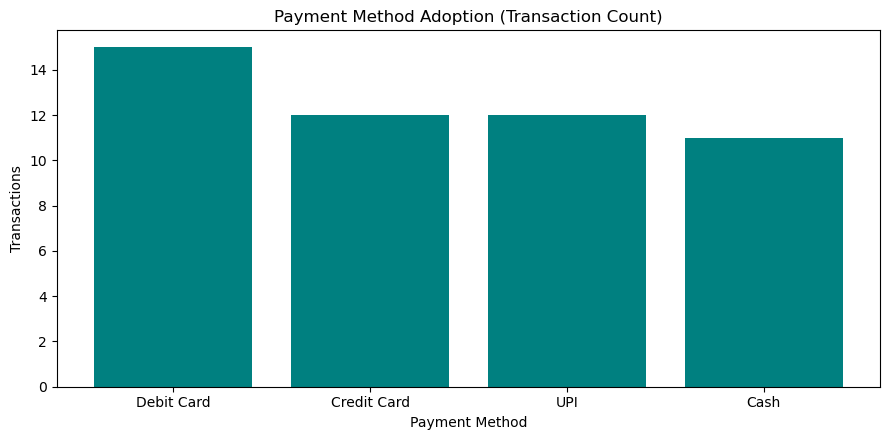

In [9]:
plt.figure(figsize=(9, 4.5))

plt.bar(
    method_analysis["payment_method"],
    method_analysis["TotalTransactions"],
    color="teal"
)

plt.title("Payment Method Adoption (Transaction Count)")
plt.xlabel("Payment Method")
plt.ylabel("Transactions")
plt.tight_layout()
plt.show()

**Transaction Outcomes by Payment Method Chart**

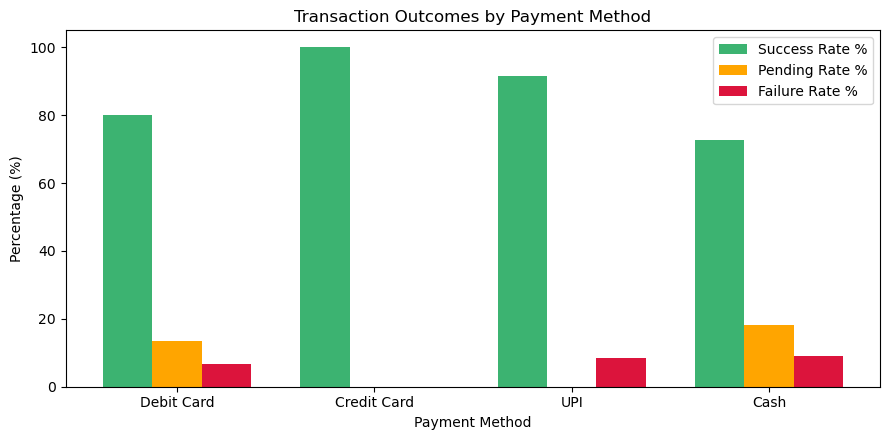

In [10]:
plt.figure(figsize=(9, 4.5))

bar_width = 0.25
r1 = np.arange(len(method_analysis))
r2 = [x + bar_width for x in r1]
r3 = [x + bar_width for x in r2]

plt.bar(r1, method_analysis["SuccessRate_%"], color="mediumseagreen", width=bar_width, label="Success Rate %")
plt.bar(r2, method_analysis["PendingRate_%"], color="orange", width=bar_width, label="Pending Rate %")
plt.bar(r3, method_analysis["FailureRate_%"], color="crimson", width=bar_width, label="Failure Rate %")

plt.xlabel("Payment Method")
plt.ylabel("Percentage (%)")
plt.title("Transaction Outcomes by Payment Method")
plt.xticks([r + bar_width for r in range(len(method_analysis))], method_analysis["payment_method"])
plt.legend()
plt.tight_layout()
plt.show()

**Order Basket Size vs. Failure Analysis**

**Failure and Pending Rates across Order Sizes**

In [11]:
order_size_analysis = (
    master_data
    .groupby("OrderSizeBin", observed=True)
    .agg(
        TotalTransactions=("payment_id", "count"),
        Paid=("payment_status", lambda x: (x == "Paid").sum()),
        Pending=("payment_status", lambda x: (x == "Pending").sum()),
        Failed=("payment_status", lambda x: (x == "Failed").sum()),
        TotalGrossValue=("order_amount", "sum"),
        AvgOrderValue=("order_amount", "mean")
    )
    .reset_index()
)

order_size_analysis["SuccessRate_%"] = (order_size_analysis["Paid"] / order_size_analysis["TotalTransactions"]) * 100
order_size_analysis["PendingRate_%"] = (order_size_analysis["Pending"] / order_size_analysis["TotalTransactions"]) * 100
order_size_analysis["FailureRate_%"] = (order_size_analysis["Failed"] / order_size_analysis["TotalTransactions"]) * 100

order_size_analysis

,OrderSizeBin,TotalTransactions,Paid,Pending,Failed,TotalGrossValue,AvgOrderValue,SuccessRate_%,PendingRate_%,FailureRate_%
0,Low (<500),12,11,0,1,4918.11,409.842500,91.666667,0.000000,8.333333
1,Medium (500-1000),16,13,2,1,11785.49,736.593125,81.250000,12.500000,6.250000
2,High (1000-1500),12,10,2,0,14724.81,1227.067500,83.333333,16.666667,0.000000
3,Very High (>1500),10,9,0,1,16411.32,1641.132000,90.000000,0.000000,10.000000


**Detailed Investigation: Failed & Pending Transactions**

**Failed Transactions Inspection (Direct Lost Sales)**

In [12]:
failed_df = master_data[master_data["payment_status"] == "Failed"]
failed_df[["payment_id", "order_id", "payment_method", "order_amount", "discount", "NetRevenue", "order_status"]]

,payment_id,order_id,payment_method,order_amount,discount,NetRevenue,order_status
28,29,29,Cash,967.07,100,867.07,Cancelled
41,42,42,UPI,452.86,75,377.86,Delivered
44,45,45,Debit Card,1615.34,0,1615.34,Delivered


**Pending Transactions Inspection (Revenue At-Risk)**

In [13]:
pending_df = master_data[master_data["payment_status"] == "Pending"]
pending_df[["payment_id", "order_id", "payment_method", "order_amount", "discount", "NetRevenue", "order_status"]]

,payment_id,order_id,payment_method,order_amount,discount,NetRevenue,order_status
1,2,2,Cash,1156.11,50,1106.11,Delivered
10,11,11,Cash,500.40,100,400.40,Cancelled
34,35,35,Debit Card,709.90,0,709.90,Delivered
49,50,50,Debit Card,1362.30,0,1362.30,Pending
